In [2]:
import session_info
import pandas as pd
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np
from datasets import load_dataset
from dotenv.ipython import load_dotenv
import session_info
import matplotlib.pyplot as plt

c:\AcadimicProjects\python_uv_workspace\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
corpus = load_dataset("stanfordnlp/imdb")
print(type(corpus))
print(corpus)

<class 'datasets.dataset_dict.DatasetDict'>
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [4]:
train_df = corpus["train"].to_pandas()
train_df["sentiment"] = np.where(train_df.label == 1, "positive", "negative")

In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       25000 non-null  str  
 1   label      25000 non-null  int64
 2   sentiment  25000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 32.4 MB


In [6]:
train_df.label.value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [7]:
train_df.sample(6)

,text,label,sentiment
7290,I HATE plane crash movies...ALL of them! In fa...,0,negative
23548,I've always liked this John Frankenheimer film...,1,positive
10171,This movie is a disgrace to the Major League F...,0,negative
23737,"High energy Raoul Walsh classic from 1933, The...",1,positive
11111,"""I Love New York"" is another entry by VH-1 (MT...",0,negative
17991,"I saw this movie yesterday on Turner, and I wa...",1,positive


<Axes: >

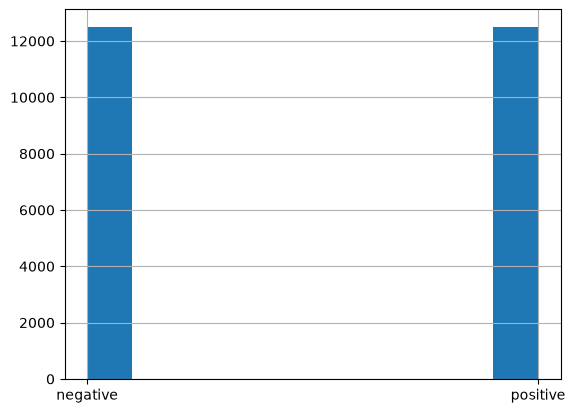

In [8]:
train_df.sentiment.hist()

In [9]:
examples_df, gold_examples_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df["sentiment"],
)

In [11]:
gold_examples_df.shape

(5000, 3)

In [15]:
columns = ['text', 'sentiment']
gold_examples = (
    gold_examples_df.loc[:, columns]
    .sample(20, random_state=42)
    .to_json(orient='records')
)

In [26]:
import json
json.loads(gold_examples)[1]

{'text': 'A fondly-remembered melodrama \x96 thanks chiefly to Ronald Colman\'s fine Oscar-winning central performance \x96 about an oft-treated theme: the nature of acting and how it can overtake one\'s perception of reality. In this case, we have a well-known thespian tackling Shakespeare\'s "Othello", so that the film\'s last third delves effectively into the thriller genre \x96 with press agent Edmond O\'Brien (who happens to really be besotted with Colman\'s co-star and ex-wife Signe Hasso) \'investigating\' the actor\'s possible involvement in the Desdemona-like strangling of a celebrity-seeking waitress (a very slim Shelley Winters). The theatrical/New York atmosphere of the immediate post-war era is vividly captured by the husband-and-wife screen writing team of Garson Kanin and Ruth Gordon and legendary "actor\'s director" George Cukor (all of whom were recognized by the Academy with nominations); incidentally, the film nabbed a second Oscar for Miklos Rozsa\'s eclectic score.

In [27]:
zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

zero_shot_prompt = [{'role': 'system', 'content': zero_shot_system_message}]

In [28]:
few_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

def create_examples(dataset, n=4):
    positive_reviews = (dataset.sentiment == 'positive')
    negative_reviews = (dataset.sentiment == 'negative')
    columns_to_select = ['text', 'sentiment']
    positive_examples = dataset.loc[positive_reviews, columns_to_select].sample(n)
    negative_examples = dataset.loc[negative_reviews, columns_to_select].sample(n)
    examples = pd.concat([positive_examples, negative_examples])
    # sampling without replacement is equivalent to random shuffling
    randomized_examples = examples.sample(2*n, replace=False)
    return randomized_examples.to_json(orient='records')

In [33]:
examples = create_examples(examples_df, 2)

In [34]:
json.loads(examples)

[{'text': "there was some truth to this movie. I remember a story reported 15 to 20 years ago of 4 fisherman finding a body in the water and they chose not to report it until their trip was finished. I also recall they were charged with interfering with a corpse (or some such charge). I'm not sure if it was in Australia. The viewers outside of Australia must think we live in a country full of rapists and serial murders. Wolf Creek and this film would encourage this perception. The film itself reminded me of A Simple Plan. But as far a being one of the best Australian films ever, as someone claimed, I can't be that generous. Put it this way, I wouldn't bother watching it again.",
  'sentiment': 'negative'},
 {'text': "I love this movie, but the music at all the alumni gatherings is just stupid.<br /><br />The fateful game took place in 1972. That means that the protagonists graduated in 1972. But almost all of the music played at the dances etc. is from the 1950s and very early 1960s.<b

In [35]:
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [
        {'role': 'system', 'content': system_message}
    ]
    for example in json.loads(examples):
        example_review = example['text']
        example_sentiment = example['sentiment']
        few_shot_prompt.append(
            {
                'role': 'user',
                'content': user_message_template.format(
                    movie_review=example_review
                )
            }
        )
        few_shot_prompt.append(
            {
                'role': 'assistant',
                'content': f"{example_sentiment}"
            }
        )
    return few_shot_prompt

In [36]:
user_message_template = """```{movie_review}```"""

In [37]:
examples = create_examples(examples_df, 4)
few_shot_prompt = create_prompt(
    few_shot_system_message,
    examples,
    user_message_template
)

In [41]:
cot_system_message = """
Classify the sentiment of movie reviews presented in the input
as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the
input.
Answer only 'positive' or 'negative'
Do not explain your answer.
Instructions:
1. Carefully read the text of the review and think through the
options for sentiment provided
2. Consider the overall sentiment of the review and estimate
the probability of the review being positive
To reiterate, your answer should strictly only contain the
label: positive or negative
"""

cot_few_shot_prompt = create_prompt(
cot_system_message,
examples,
user_message_template
)

Evaluation des promptes

In [38]:
def evaluate_prompt(prompt, gold_examples, user_message_template, model):
    model_predictions, ground_truths = [], []

    for example in json.loads(gold_examples):
        gold_input = example['text']
        user_input = [
            {
                'role': 'user',
                'content': user_message_template.format(movie_review=gold_input)
            }
        ]
        try:
            response = model.invoke(prompt + user_input)

            if hasattr(response, 'content'):
                response_content = response.content
            else:
                response_content = response

            if 'negative' in response_content.strip().lower():
                prediction = 'negative'
            elif 'positive' in response_content.strip().lower():
                prediction = 'positive'
            else:
                prediction = 'unknown'

            model_predictions.append(prediction)
            ground_truths.append(example['sentiment'])
        except Exception as e:
            print(e)
            continue

    micro_f1_score = f1_score(ground_truths, model_predictions, average="micro")
    return micro_f1_score

In [39]:
import os
from langchain_ollama import ChatOllama

load_dotenv(override=True)

api_key = os.getenv("OLLAMA_API_KEY")

llm = ChatOllama(
    model="gemma4:31b",   
    base_url="https://ollama.com",
    client_kwargs={"headers": {"Authorization": f"Bearer {api_key}"}},
    temperature=0,
)

In [42]:
evaluate_prompt(zero_shot_prompt, gold_examples, user_message_template, llm)
evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm)
evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm)

0.95

In [44]:
num_eval_runs = 10
few_shot_performance, cot_few_shot_performance = [], []

for _ in tqdm(range(num_eval_runs)):
    # Nouveau tirage d'exemples à chaque run
    examples = create_examples(examples_df)

    few_shot_prompt = create_prompt(
        few_shot_system_message, examples, user_message_template
    )
    cot_few_shot_prompt = create_prompt(
        cot_system_message, examples, user_message_template
    )

    few_shot_micro_f1 = evaluate_prompt(
        few_shot_prompt, gold_examples, user_message_template, llm
    )
    cot_micro_f1 = evaluate_prompt(
        cot_few_shot_prompt, gold_examples, user_message_template, llm
    )

    few_shot_performance.append(few_shot_micro_f1)
    cot_few_shot_performance.append(cot_micro_f1)

# Résultats
for name, perf in [("Few-shot", few_shot_performance), ("CoT", cot_few_shot_performance)]:
    mean_val = np.array(perf).mean()
    std_val = np.array(perf).std()
    print(f"{name} - f1_score Moyen = {mean_val}, Standard Deviation = {std_val}")

100%|██████████| 10/10 [04:40<00:00, 28.00s/it]

Few-shot - f1_score Moyen = 0.9499999999999998, Standard Deviation = 1.1102230246251565e-16
CoT - f1_score Moyen = 0.9499999999999998, Standard Deviation = 1.1102230246251565e-16
